In [ ]:
import numpy as np
import pandas as pd

In [2]:
# Load the dataset using Pandas. 

df = pd.read_csv("banking_fraud_data_10000.csv")
print(df)

     Transaction_ID Customer_ID   Age           City  Transaction_Amount  \
0         TXN000001   CUST00224  51.0         Mumbai            20165.96   
1         TXN000002   CUST01935  27.0      Bengaluru            80057.08   
2         TXN000003   CUST01637  37.0      Bengaluru            11593.67   
3         TXN000004   CUST01098  54.0        Chennai            11208.39   
4         TXN000005   CUST01083  54.0      Bengaluru            12673.87   
...             ...         ...   ...            ...                 ...   
9995      TXN009996   CUST01178  45.0      Hyderabad            20955.86   
9996      TXN009997   CUST02492  25.0         Mumbai            22601.72   
9997      TXN009998   CUST00883  39.0      Hyderabad            17599.32   
9998      TXN009999   CUST01414  66.0  Visakhapatnam             6188.04   
9999      TXN010000   CUST01539  62.0        Chennai            22368.53   

     Transaction_Type  Account_Balance Device_Type Location_Change  \
0                

(I.) Introduction 

This project analyzes financial transaction data to identify patterns and indicators associated with fraudulent transactions. Exploratory Data Analysis (EDA), data cleaning, visualization, and feature engineering are used to understand transaction behavior and identify potentially suspicious activities.

--------------------------------------------------------------------------------

(II.) Business Problem

The objective is to identify transaction patterns that may indicate fraud and help a bank detect potentially suspicious transactions. The analysis focuses on transaction amount, transaction type, device type, location changes, transaction time, and failed transaction attempts.

In [3]:
# Phase 1 - Understand the data 

# Display the first 5 rows. 
df.head(5)

,Transaction_ID,Customer_ID,Age,City,Transaction_Amount,Transaction_Type,Account_Balance,Device_Type,Location_Change,Transaction_Time_Hour,Is_Weekend,Failed_Transactions_Last_24h,Is_Fraud
0,TXN000001,CUST00224,51.0,Mumbai,20165.96,ATM,11695.06,ATM,No,10.0,Yes,0.0,0
1,TXN000002,CUST01935,27.0,Bengaluru,80057.08,Online,67506.61,Mobile,Yes,17.0,No,0.0,0
2,TXN000003,CUST01637,37.0,Bengaluru,11593.67,POS,44740.16,Mobile,Yes,4.0,Yes,1.0,1
3,TXN000004,CUST01098,54.0,Chennai,11208.39,POS,261985.75,Mobile,No,20.0,No,0.0,0
4,TXN000005,CUST01083,54.0,Bengaluru,12673.87,Online,21390.58,Mobile,No,11.0,No,0.0,0


In [4]:
# Display the last 5 rows. 

df.tail(5)

,Transaction_ID,Customer_ID,Age,City,Transaction_Amount,Transaction_Type,Account_Balance,Device_Type,Location_Change,Transaction_Time_Hour,Is_Weekend,Failed_Transactions_Last_24h,Is_Fraud
9995,TXN009996,CUST01178,45.0,Hyderabad,20955.86,POS,105949.88,Card,Yes,0.0,No,1.0,0
9996,TXN009997,CUST02492,25.0,Mumbai,22601.72,Online,20853.03,Mobile,No,8.0,No,1.0,0
9997,TXN009998,CUST00883,39.0,Hyderabad,17599.32,Online,113282.82,Laptop,Yes,9.0,No,0.0,0
9998,TXN009999,CUST01414,66.0,Visakhapatnam,6188.04,Online,207406.67,Mobile,Yes,12.0,No,2.0,0
9999,TXN010000,CUST01539,62.0,Chennai,22368.53,Online,23857.63,Mobile,No,8.0,No,0.0,0


In [5]:
# Find the number of rows and columns. 

print(df.shape)
rows_columns = df.shape
print("No.of Rows:- ", rows_columns[0] )
print("No.of Columns:- ", rows_columns[1] )

(10000, 13)
No.of Rows:-  10000
No.of Columns:-  13


In [6]:
# Display column names. 

print(df.columns)

Index(['Transaction_ID', 'Customer_ID', 'Age', 'City', 'Transaction_Amount',
       'Transaction_Type', 'Account_Balance', 'Device_Type', 'Location_Change',
       'Transaction_Time_Hour', 'Is_Weekend', 'Failed_Transactions_Last_24h',
       'Is_Fraud'],
      dtype='str')


In [7]:
# Check data types. 

print(df.dtypes)

Transaction_ID                      str
Customer_ID                         str
Age                             float64
City                                str
Transaction_Amount              float64
Transaction_Type                    str
Account_Balance                 float64
Device_Type                         str
Location_Change                     str
Transaction_Time_Hour           float64
Is_Weekend                          str
Failed_Transactions_Last_24h    float64
Is_Fraud                          int64
dtype: object


In [8]:
# Generate dataset information using info(). 
print( "Dataset information using info:- \n" ,print(df.info()))

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 13 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Transaction_ID                10000 non-null  str    
 1   Customer_ID                   10000 non-null  str    
 2   Age                           9975 non-null   float64
 3   City                          9980 non-null   str    
 4   Transaction_Amount            9982 non-null   float64
 5   Transaction_Type              9985 non-null   str    
 6   Account_Balance               9978 non-null   float64
 7   Device_Type                   9985 non-null   str    
 8   Location_Change               9988 non-null   str    
 9   Transaction_Time_Hour         9985 non-null   float64
 10  Is_Weekend                    9990 non-null   str    
 11  Failed_Transactions_Last_24h  9985 non-null   float64
 12  Is_Fraud                      10000 non-null  int64  
dtypes: float64(5)

In [9]:
# Generate statistical summary using describe().  
print( "Stastical summary using describe:- \n" , df.describe())

Stastical summary using describe:- 
                Age  Transaction_Amount  Account_Balance  \
count  9975.000000        9.982000e+03      9978.000000   
mean     45.644311        4.260766e+04     78758.417265   
std      14.501716        1.366359e+05     76203.640283   
min      12.000000       -4.862600e+03    -19234.130000   
25%      33.000000        7.982452e+03     30835.890000   
50%      46.000000        1.428474e+04     55028.580000   
75%      58.000000        2.555225e+04     98364.657500   
max     108.000000        1.789817e+06    500000.000000   

       Transaction_Time_Hour  Failed_Transactions_Last_24h      Is_Fraud  
count            9985.000000                   9985.000000  10000.000000  
mean               12.959740                      0.847872      0.131400  
std                 6.102521                      0.906370      0.337854  
min                -5.000000                      0.000000      0.000000  
25%                 8.000000                      0.0000

In [11]:
# Identify categorical and numerical columns. 

numerical_col = df.select_dtypes(include = "number").columns.tolist()
categorical_col = df.select_dtypes(include=['object', 'category']).columns.tolist()

print("Numerical columns:- ", numerical_col)
print("---------------------------------")
print("Categorical columns:- ",categorical_col)

Numerical columns:-  ['Age', 'Transaction_Amount', 'Account_Balance', 'Transaction_Time_Hour', 'Failed_Transactions_Last_24h', 'Is_Fraud']
---------------------------------
Categorical columns:-  ['Transaction_ID', 'Customer_ID', 'City', 'Transaction_Type', 'Device_Type', 'Location_Change', 'Is_Weekend']


C:\Users\ADMIN\AppData\Local\Temp\ipykernel_696\138714199.py:4: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_col = df.select_dtypes(include=['object', 'category']).columns.tolist()


In [12]:
# Find the number of unique customers. 

print( "Unique Customers:- " , df["Customer_ID"].value_counts().count())

Unique Customers:-  2451


In [13]:
# Find the number of unique transactions.  

print( "Number of Unique Transactions:- " ,df["Transaction_ID"].value_counts().count())

Number of Unique Transactions:-  10000


In [14]:
# Find unique transaction types.

print( "Number of Unique Transactions:- " ,df["Transaction_Type"].value_counts().count())

Number of Unique Transactions:-  3


In [15]:
# Find unique device types. 

print("Unique Device Types:- ", df["Device_Type"].value_counts().count())   

Unique Device Types:-  4


In [16]:
# • Find unique cities.  

print("Unique Cities:- ", df["City"].value_counts().count())  

Unique Cities:-  8


In [17]:
# 1. How many transactions are present? 

print("No.of Transactions are present: ", df["Transaction_ID"].value_counts().count())

No.of Transactions are present:  10000


In [18]:
# 2. How many customers are present? 
print("No.of Customers are present: ", df["Customer_ID"].value_counts().count())

No.of Customers are present:  2451


In [19]:
# 3. What types of transactions are available? 

print( "Types Transactions:- \n" ,df["Transaction_Type"].value_counts())

Types Transactions:- 
 Transaction_Type
Online    5158
POS       2502
ATM       2325
Name: count, dtype: int64


In [20]:
# 4. Which columns are numerical? 

numerical_col = df.select_dtypes(include = "number").columns.tolist()
print("Numerical columns:- ", numerical_col)

Numerical columns:-  ['Age', 'Transaction_Amount', 'Account_Balance', 'Transaction_Time_Hour', 'Failed_Transactions_Last_24h', 'Is_Fraud']


In [21]:
# 5. Which columns are categorical?

categorical_col = df.select_dtypes(include=['object', 'category']).columns.tolist()
print("Categorical columns:- ",categorical_col)

Categorical columns:-  ['Transaction_ID', 'Customer_ID', 'City', 'Transaction_Type', 'Device_Type', 'Location_Change', 'Is_Weekend']


C:\Users\ADMIN\AppData\Local\Temp\ipykernel_696\1666890397.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_col = df.select_dtypes(include=['object', 'category']).columns.tolist()


In [22]:
# Phase 2 – Data Quality Investigation 

# Which columns contain missing values? 

null_columns = df.columns[df.isnull().any()].tolist()       # any() will find, any true(is null) from column, all the columns converted to list
print(null_columns)

['Age', 'City', 'Transaction_Amount', 'Transaction_Type', 'Account_Balance', 'Device_Type', 'Location_Change', 'Transaction_Time_Hour', 'Is_Weekend', 'Failed_Transactions_Last_24h']


In [25]:
# • How many missing values are present? 

null_counts = df.isnull().sum()    # find each null value and added to gether for each column
print(null_counts)
print("-------------------------------")
print( "Total missing values count:- " , null_counts.sum())            # sum all the null values count from columns.

Transaction_ID                   0
Customer_ID                      0
Age                             25
City                            20
Transaction_Amount              18
Transaction_Type                15
Account_Balance                 22
Device_Type                     15
Location_Change                 12
Transaction_Time_Hour           15
Is_Weekend                      10
Failed_Transactions_Last_24h    15
Is_Fraud                         0
dtype: int64
-------------------------------
Total missing values count:-  167


In [38]:
# What percentage of each column is missing? 
#####

null_counts = df.isnull().sum()    # find each null value and added to gether for each column

missing_percentage = (df.isnull().sum() / len(df)) * 100 

print( "Percent each column is missing:-\n" , missing_percentage)            

Percent each column is missing:-
 Transaction_ID                  0.00
Customer_ID                     0.00
Age                             0.25
City                            0.20
Transaction_Amount              0.18
Transaction_Type                0.15
Account_Balance                 0.22
Device_Type                     0.15
Location_Change                 0.12
Transaction_Time_Hour           0.15
Is_Weekend                      0.10
Failed_Transactions_Last_24h    0.15
Is_Fraud                        0.00
dtype: float64


In [ ]:
# Decide how you would handle the missing values. 
# Explain why you selected your approach. 

(Q.) How should we handle the missing values? Explain why you selected your approach.
(A.) As, only 167 missing value, instead deleting null values, i will replace with speacific value depends on the column. 

    (i.) For numerical columns, Median is better choice.
        Columns:- Age, Transaction_Amount, Account_Balance, Transaction_Time_Hour, Failed_Transactions_Last_24h 
        Reason:- Numerical columns has outliers. The mean is strongly affected by the very large transaction amounts.
        Example:- Transaction_Amount column has:              Mean = 42,607.66, Median = 14,284.74, Maximum = 1,789,817     
                SO, Median is safer than mean when the data contains outliers.

    (ii.) For Categorical columns, Mode is better choice. 
        Columns:- City, Transaction_Type, Device_Type, Location_Change, Is_Weekend
        Reason:- These columns contain categorical values, not numerical measurements. We cannot calculate a proper mean/median for categories. 
            SO, Mode is appropriate for categorical columns because it replaces missing values with the most frequently occurring category. 

    (iii.) Forward Fill / Backward Fill is not ideal for banking dataset. 
        Reason:- These methods copy values from neighboring rows. But dataset transactions are not necessarily sequentially related. 
    
    (iv.) Removing records also not preferrable 
        Reason:- If we remove, Missing data is very small, so removing records would cause unnecessary data loss.

In [39]:
# Phase 3 – Identify Invalid Data 

# Negative transaction amounts

print(df.loc[df["Transaction_Amount"] < 0])

     Transaction_ID Customer_ID   Age        City  Transaction_Amount  \
227       TXN000228   CUST01449  70.0  Vijayawada            -1440.99   
2284      TXN002285   CUST01703  63.0        Pune            -1691.49   
2415      TXN002416   CUST01216  50.0  Vijayawada            -3551.94   
2961      TXN002962   CUST01055  27.0     Chennai            -3676.22   
4481      TXN004482   CUST00743  45.0        Pune            -3592.13   
4905      TXN004906   CUST01604  51.0     Chennai            -2130.04   
5093      TXN005094   CUST02425  38.0   Hyderabad            -2600.43   
7052      TXN007053   CUST01698  26.0   Bengaluru            -2669.33   
7908      TXN007909   CUST00280  63.0  Vijayawada            -1033.30   
8242      TXN008243   CUST01372  21.0       Delhi            -1281.55   
8718      TXN008719   CUST01568  64.0      Mumbai            -4862.60   
9172      TXN009173   CUST00179  62.0     Chennai             -962.12   

     Transaction_Type  Account_Balance Device_Type

In [40]:
# Zero transaction amounts 

print(df.loc[df["Transaction_Amount"] == 0])

     Transaction_ID Customer_ID   Age           City  Transaction_Amount  \
118       TXN000119   CUST00614  70.0      Bengaluru                 0.0   
157       TXN000158   CUST01393  29.0      Bengaluru                 0.0   
1691      TXN001692   CUST02225  44.0      Bengaluru                 0.0   
1785      TXN001786   CUST00609  29.0      Hyderabad                 0.0   
4694      TXN004695   CUST01769  38.0      Bengaluru                 0.0   
4798      TXN004799   CUST00978  41.0      Bengaluru                 0.0   
5662      TXN005663   CUST02152  47.0      Hyderabad                 0.0   
6675      TXN006676   CUST02208  62.0           Pune                 0.0   
8577      TXN008578   CUST02486  22.0      Hyderabad                 0.0   
8607      TXN008608   CUST00876  31.0  Visakhapatnam                 0.0   
8843      TXN008844   CUST00451  60.0      Hyderabad                 0.0   
9744      TXN009745   CUST01304  43.0      Hyderabad                 0.0   

     Transa

In [41]:
# Extremely large transactions or extrmely low

Q1 = df["Transaction_Amount"].quantile(0.25)
Q3 = df["Transaction_Amount"].quantile(0.75)

IQR = Q3 - Q1
print("IQR: ", IQR)
print("-----------------------------------------------------")
lower_bound = Q1 - IQR * 1.5
upper_bound = Q3 + IQR * 1.5
print("Lower Bound = ", (Q1 - IQR * 1.5))
print("Upper Bound = ", (Q3 + IQR * 1.5))
print("------------------------------------------------------") 
print(df.iloc[(df["Transaction_Amount"] < lower_bound) | (df["Transaction_Amount"] > upper_bound )])  # | means or, as or gives value error

IQR:  17569.800000000003
-----------------------------------------------------
Lower Bound =  -18372.247500000005
Upper Bound =  51906.95250000001
------------------------------------------------------
     Transaction_ID Customer_ID   Age        City  Transaction_Amount  \
1         TXN000002   CUST01935  27.0   Bengaluru            80057.08   
6         TXN000007   CUST00215  62.0     Chennai           276648.97   
8         TXN000009   CUST00504  24.0        Pune           290207.48   
17        TXN000018   CUST00321  69.0      Mumbai           179124.47   
20        TXN000021   CUST01251  64.0     Chennai           110207.72   
...             ...         ...   ...         ...                 ...   
9951      TXN009952   CUST01030  26.0       Delhi           149776.52   
9969      TXN009970   CUST00769  34.0  Vijayawada           126453.17   
9974      TXN009975   CUST01385  33.0  Vijayawada           151703.31   
9976      TXN009977   CUST00507  22.0       Delhi            87266.6

In [42]:
# • Account balance is negative 

print(df.loc[df["Account_Balance"] < 0])

     Transaction_ID Customer_ID   Age        City  Transaction_Amount  \
1262      TXN001263   CUST01112  64.0       Delhi            23181.53   
1317      TXN001318   CUST01476  54.0   Bengaluru           118385.79   
1843      TXN001844   CUST02115  53.0     Chennai            11085.95   
1896      TXN001897   CUST01436  70.0        Pune            52864.09   
2766      TXN002767   CUST00924  26.0      Mumbai             7609.48   
3620      TXN003621   CUST02491  46.0  Vijayawada            19306.11   
5280      TXN005281   CUST01783  63.0      Mumbai            62267.87   
6800      TXN006801   CUST02129  62.0   Bengaluru            12371.38   
9031      TXN009032   CUST00751  47.0       Delhi             2568.35   
9282      TXN009283   CUST00310  24.0   Hyderabad             9623.70   

     Transaction_Type  Account_Balance Device_Type Location_Change  \
1262           Online         -1350.70      Laptop              No   
1317              POS         -4204.14        Card      

In [43]:
# • Transaction amount is greater than account balance 

print(df.loc[df["Transaction_Amount"] > df["Account_Balance"]])

     Transaction_ID Customer_ID   Age       City  Transaction_Amount  \
0         TXN000001   CUST00224  51.0     Mumbai            20165.96   
1         TXN000002   CUST01935  27.0  Bengaluru            80057.08   
6         TXN000007   CUST00215  62.0    Chennai           276648.97   
8         TXN000009   CUST00504  24.0       Pune           290207.48   
17        TXN000018   CUST00321  69.0     Mumbai           179124.47   
...             ...         ...   ...        ...                 ...   
9971      TXN009972   CUST00833  37.0      Delhi            35964.20   
9976      TXN009977   CUST00507  22.0      Delhi            87266.61   
9983      TXN009984   CUST02138  35.0     Mumbai            21820.06   
9992      TXN009993   CUST02293  40.0  Bengaluru            14300.58   
9996      TXN009997   CUST02492  25.0     Mumbai            22601.72   

     Transaction_Type  Account_Balance Device_Type Location_Change  \
0                 ATM         11695.06         ATM              N

In [44]:
# Age 
# Unrealistic ages 

print(df.loc[df["Age"] <= 18])

     Transaction_ID Customer_ID   Age       City  Transaction_Amount  \
844       TXN000845   CUST00014  17.0     Mumbai            40596.62   
969       TXN000970   CUST00091  12.0       Pune             8816.05   
1153      TXN001154   CUST02274  12.0  Bengaluru             9141.24   
1475      TXN001476   CUST00756  17.0    Chennai            11737.98   
2223      TXN002224   CUST01058  16.0      Delhi            18917.53   
2718      TXN002719   CUST01450  13.0     Mumbai            22646.89   
3145      TXN003146   CUST01381  16.0    Chennai            14420.87   
5304      TXN005305   CUST00586  17.0  Hyderabad             4354.64   
9604      TXN009605   CUST01082  16.0       Pune             6912.32   

     Transaction_Type  Account_Balance Device_Type Location_Change  \
844            Online         33162.56      Laptop             Yes   
969            Online        104488.14      Mobile              No   
1153           Online         36086.98      Mobile             Yes   

In [45]:
# • Extremely low values 

Q1 = df["Age"].quantile(0.25)
Q3 = df["Age"].quantile(0.75)

IQR = Q3 - Q1
print("IQR: ", IQR)
print("-----------------------------------------------------")
lower_bound = Q1 - IQR * 1.5
upper_bound = Q3 + IQR * 1.5
print("Lower Bound = ", (Q1 - IQR * 1.5))
print("Upper Bound = ", (Q3 + IQR * 1.5))
print("------------------------------------------------------") 
print(df.loc[df["Age"] < lower_bound])

IQR:  25.0
-----------------------------------------------------
Lower Bound =  -4.5
Upper Bound =  95.5
------------------------------------------------------
Empty DataFrame
Columns: [Transaction_ID, Customer_ID, Age, City, Transaction_Amount, Transaction_Type, Account_Balance, Device_Type, Location_Change, Transaction_Time_Hour, Is_Weekend, Failed_Transactions_Last_24h, Is_Fraud]
Index: []


In [46]:
# • Extremely high values
print(df.loc[df["Age"] > upper_bound])

     Transaction_ID Customer_ID    Age           City  Transaction_Amount  \
92        TXN000093   CUST02105  101.0        Chennai            20859.66   
2667      TXN002668   CUST02414  108.0  Visakhapatnam            21765.55   
3056      TXN003057   CUST02006  103.0      Hyderabad             3759.97   
3658      TXN003659   CUST00838   98.0      Hyderabad             5924.58   
4392      TXN004393   CUST00031  108.0          Delhi            11345.25   
5500      TXN005501   CUST02365  103.0     Vijayawada           133210.59   
7927      TXN007928   CUST00685  104.0         Mumbai           211916.71   
9490      TXN009491   CUST00564  103.0     Vijayawada            22549.64   

     Transaction_Type  Account_Balance Device_Type Location_Change  \
92             Online          7274.77      Mobile             Yes   
2667           Online         29909.79      Laptop              No   
3056              ATM         76004.78         ATM             Yes   
3658              ATM     

In [47]:
# Transaction_Time_Hour is between: 0 and 23

df["Transaction_Time_Hour"].between(0,23).value_counts()

Transaction_Time_Hour
True     9969
False      31
Name: count, dtype: int64

In [49]:
# 1. Which records contain invalid values? 
df.head()

,Transaction_ID,Customer_ID,Age,City,Transaction_Amount,Transaction_Type,Account_Balance,Device_Type,Location_Change,Transaction_Time_Hour,Is_Weekend,Failed_Transactions_Last_24h,Is_Fraud
0,TXN000001,CUST00224,51.0,Mumbai,20165.96,ATM,11695.06,ATM,No,10.0,Yes,0.0,0
1,TXN000002,CUST01935,27.0,Bengaluru,80057.08,Online,67506.61,Mobile,Yes,17.0,No,0.0,0
2,TXN000003,CUST01637,37.0,Bengaluru,11593.67,POS,44740.16,Mobile,Yes,4.0,Yes,1.0,1
3,TXN000004,CUST01098,54.0,Chennai,11208.39,POS,261985.75,Mobile,No,20.0,No,0.0,0
4,TXN000005,CUST01083,54.0,Bengaluru,12673.87,Online,21390.58,Mobile,No,11.0,No,0.0,0


(1.) Which records contain invalid values? 

(A.) In Trasaction amount column, 
        Negative trasaction amounts are in 12 rows,
        Zero transaction amounts are in 12 rows, 
        extremely high transaction amounts are in 1238 rows. 
     In Age, 8 rows are with high age ( greater than 100) can be outliers.
     Transaction_Time_Hour has 31 invalid records.

In [ ]:
#2. Should these records be removed or corrected? 


(2.) Should these records be removed or corrected? 

(A.) Correct them, if the correct value is known (or) Replace it with mean, median, mode .Remove the record only if it cannot be reliably corrected and is unsuitable for analysis. 

In [ ]:
# 3. What assumptions did you make? 

(3.) What assumptions did you make?  

(A.) 
 
1.) Transaction_Amount should normally be greater than or equal to zero.
2.) Negative transaction amounts are considered invalid for this transaction dataset. 
3.) Zero-value transactions are considered suspicious and require business-rule confirmation. 
4.) Extremely large transaction amounts are treated as outliers rather than automatically invalid or fraudulent.
5.) Negative account balances may be valid if overdrafts are supported, so they require further investigation.
6.) Transaction_Time_Hour must be between 0 and 23.
7.) Ages above 100 are considered suspicious, but not automatically invalid without a defined business rule.
8.) Records should not be deleted unless the value is confirmed to be erroneous or cannot reasonably be corrected.

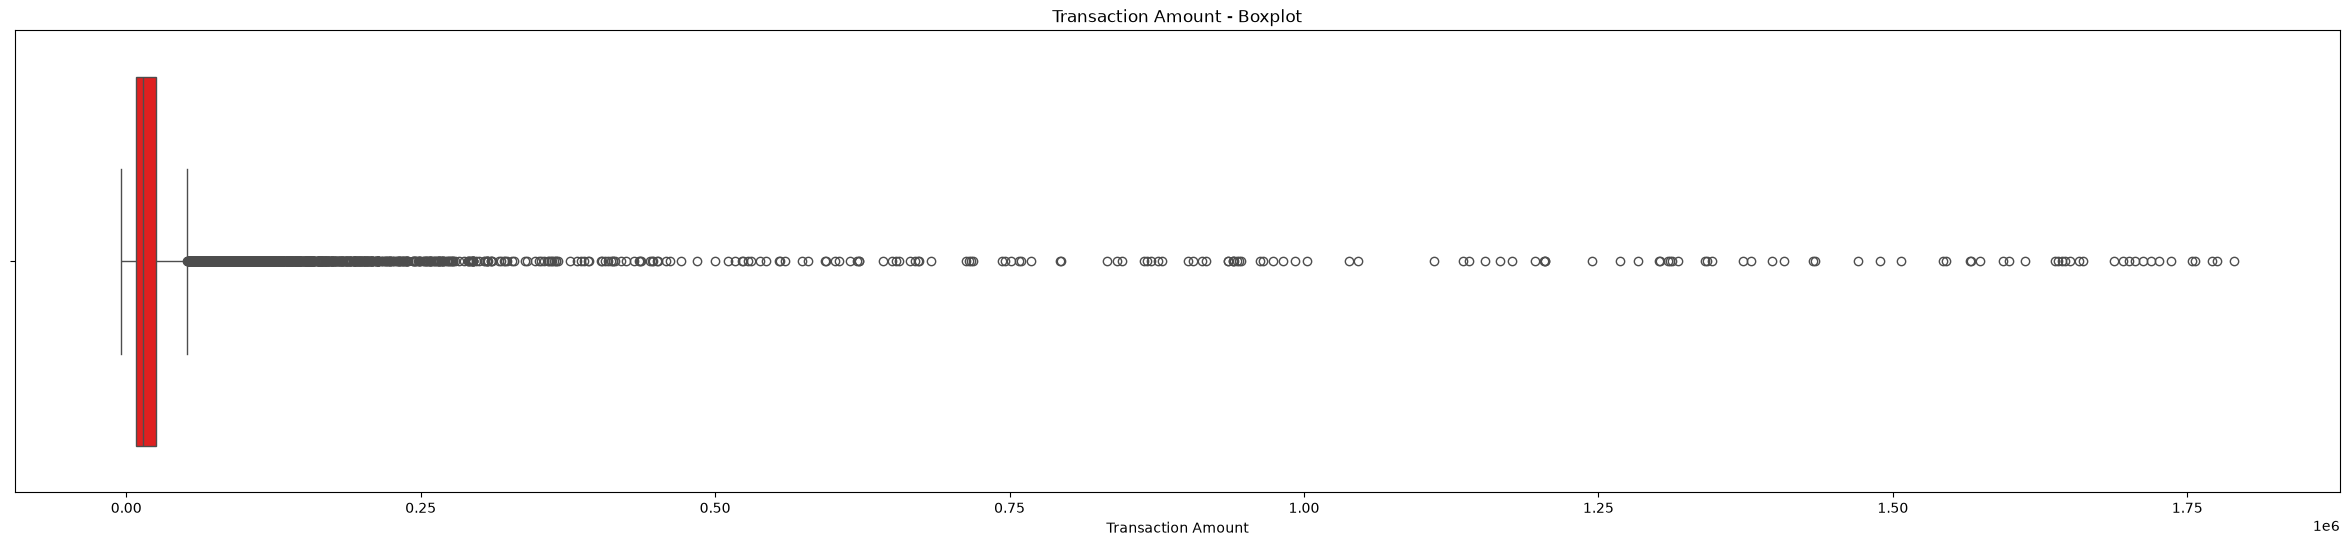

In [50]:
# Phase 4 – Outlier Detection 

# Method 1 – Boxplot 

# Create a boxplot for: Transaction_Amount 

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(30, 6))

sns.boxplot(data = df, x = "Transaction_Amount", color = "red")

plt.title("Transaction Amount - Boxplot")
plt.xlabel("Transaction Amount")

plt.show()

In [51]:
# Method 2 – IQR Method 

Q1 = df["Transaction_Amount"].quantile(0.25)
Q3 = df["Transaction_Amount"].quantile(0.75)

print("Q1: ", Q1)
print("Q3: ", Q3)

IQR = Q3 - Q1
print("IQR: ", IQR)
print("-----------------------------------------------------")
lower_bound = Q1 - IQR * 1.5
upper_bound = Q3 + IQR * 1.5
print("Lower Bound = ", (Q1 - IQR * 1.5))
print("Upper Bound = ", (Q3 + IQR * 1.5))
print("----------------------------------------------------")
print(df.loc[(df["Transaction_Amount"] < lower_bound) | (df["Transaction_Amount"] > upper_bound)])


Q1:  7982.452499999999
Q3:  25552.252500000002
IQR:  17569.800000000003
-----------------------------------------------------
Lower Bound =  -18372.247500000005
Upper Bound =  51906.95250000001
----------------------------------------------------
     Transaction_ID Customer_ID   Age        City  Transaction_Amount  \
1         TXN000002   CUST01935  27.0   Bengaluru            80057.08   
6         TXN000007   CUST00215  62.0     Chennai           276648.97   
8         TXN000009   CUST00504  24.0        Pune           290207.48   
17        TXN000018   CUST00321  69.0      Mumbai           179124.47   
20        TXN000021   CUST01251  64.0     Chennai           110207.72   
...             ...         ...   ...         ...                 ...   
9951      TXN009952   CUST01030  26.0       Delhi           149776.52   
9969      TXN009970   CUST00769  34.0  Vijayawada           126453.17   
9974      TXN009975   CUST01385  33.0  Vijayawada           151703.31   
9976      TXN009977   C

In [53]:
# 1. How many outliers are present? 

Outliers_count = df.loc[(df["Transaction_Amount"] < lower_bound) | (df["Transaction_Amount"] > upper_bound)].count().sum() 
print("Total no.of outliers:-", Outliers_count)

Total no.of outliers:- 16076


In [54]:
# 2. Which transactions are outliers? 

df.loc[(df["Transaction_Amount"] < lower_bound) | (df["Transaction_Amount"] > upper_bound)]

,Transaction_ID,Customer_ID,Age,City,Transaction_Amount,Transaction_Type,Account_Balance,Device_Type,Location_Change,Transaction_Time_Hour,Is_Weekend,Failed_Transactions_Last_24h,Is_Fraud
1,TXN000002,CUST01935,27.0,Bengaluru,80057.08,Online,67506.61,Mobile,Yes,17.0,No,0.0,0
6,TXN000007,CUST00215,62.0,Chennai,276648.97,Online,98553.66,Mobile,No,21.0,No,0.0,1
8,TXN000009,CUST00504,24.0,Pune,290207.48,Online,28643.11,Mobile,No,7.0,No,1.0,0
17,TXN000018,CUST00321,69.0,Mumbai,179124.47,POS,166659.69,Card,No,17.0,Yes,0.0,0
20,TXN000021,CUST01251,64.0,Chennai,110207.72,Online,18275.72,Mobile,No,6.0,Yes,1.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
9951,TXN009952,CUST01030,26.0,Delhi,149776.52,ATM,41391.36,ATM,No,6.0,Yes,0.0,1
9969,TXN009970,CUST00769,34.0,Vijayawada,126453.17,Online,96936.33,Laptop,No,15.0,Yes,1.0,0
9974,TXN009975,CUST01385,33.0,Vijayawada,151703.31,Online,173158.78,Mobile,No,14.0,No,2.0,0
9976,TXN009977,CUST00507,22.0,Delhi,87266.61,ATM,73781.50,ATM,No,19.0,No,0.0,0


In [ ]:
# 3. Are all outliers fraudulent? 

(3.) Are all outliers fraudulent? 

(A.) No. 
    Reason:- An outlier is an data entry that is significantly different from most other values. 
    An outlier can be:- A legitimate transaction, A data-entry error, A rare customer behavior, A potentially fraudulent transaction. Therefore, outlier ≠ fraud.
    
    Example:- A customer normally makes transactions around ₹10,000, but one transaction is ₹10,00,000. That transaction is an outlier, but it could be a legitimate purchase such as buying a car or property.

In [ ]:
# 4. Should an outlier automatically be considered fraud? 

(4.) Should an outlier automatically be considered fraud?

(A.) Correct answer: No.
    Reason:- An outlier should be treated as a signal for further investigation, not automatically labeled as fraud.

In [ ]:
""" 
Is an outlier necessarily an error? 
Think carefully before removing an extreme transaction. 
A ₹10,00,000 transaction may be unusual, but it could still be a legitimate transaction. 
"""

(4.) Is an outlier necessarily an error?

(A.) No. An outlier is not necessarily an error. 
    Example:- In dataset, Median of Transactions is 14,284.74. But, highest transaction in the column is 17,89,817. It is an outlier. But, we need to go further to find why trasaction is unusal, rather than thinking it as a error.

In [55]:
# Phase 5 – NumPy Analysis 

# Mean transaction amount 
print("Mean of transaction amount:- ",df["Transaction_Amount"].mean())

Mean of transaction amount:-  42607.65686936486


In [56]:
# • Median transaction amount 
print("Median of transaction amount:- ",df["Transaction_Amount"].median())

Median of transaction amount:-  14284.74


In [57]:
# • Standard deviation 
print("Standard deviation of transaction amount:- ",np.std(df["Transaction_Amount"]))

Standard deviation of transaction amount:-  136629.0279395683


In [58]:
# • Minimum transaction amount 
print("Minimum transaction amount:- ",df["Transaction_Amount"].min())

Minimum transaction amount:-  -4862.6


In [59]:
# • Maximum transaction amount 
print("Maximum transaction amount :- ",df["Transaction_Amount"].max())

Maximum transaction amount :-  1789817.42


In [60]:
# • Percentiles 

Q1 = df["Transaction_Amount"].quantile(0.25)
Median = df["Transaction_Amount"].quantile(0.50)
Q3 = df["Transaction_Amount"].quantile(0.75)
print("Q1: ", Q1)
print("Median: ",Median)
print("Q3: ", Q3)


Q1:  7982.452499999999
Median:  14284.74
Q3:  25552.252500000002


In [67]:
# Compare Fraudulent Transactions with Non-Fraudulent Transactions 

print(df["Is_Fraud"].value_counts())

# 8686 transactions are Non-Fraudulent Transactions, 1314 transactions are Fraudulent Transactions

Is_Fraud
0    8686
1    1314
Name: count, dtype: int64


In [61]:
# • Mean transaction amount 
print("Mean of transaction amount:- ",df["Transaction_Amount"].mean())

Mean of transaction amount:-  42607.65686936486


In [62]:
# • Median transaction amount 
print("Median of transaction amount:- ",df["Transaction_Amount"].median())

Median of transaction amount:-  14284.74


In [63]:
# • Standard deviation 
print("Standard deviation of transaction amount:- ",np.std(df["Transaction_Amount"]))

Standard deviation of transaction amount:-  136629.0279395683


In [64]:
# Is the average transaction amount higher for fraudulent transactions? Support your answer with calculations.

fraud_avg = df[df["Is_Fraud"] == 1]["Transaction_Amount"].mean()                 # Average transaction amount for fraudulent transactions

non_fraud_avg = df[df["Is_Fraud"] == 0]["Transaction_Amount"].mean()           # Average transaction amount for non-fraudulent transactions

print("Average Fraudulent Transaction:", fraud_avg)
print("Average Non-Fraudulent Transaction:", non_fraud_avg)
print("------------------------------------------------------")
if fraud_avg > non_fraud_avg:
    print("Yes, the average transaction amount is higher for fraudulent transactions.")
else:
    print("No, the average transaction amount is not higher for fraudulent transactions.")

Average Fraudulent Transaction: 73737.89714939025
Average Non-Fraudulent Transaction: 37896.8292745098
------------------------------------------------------
Yes, the average transaction amount is higher for fraudulent transactions.


In [75]:
# Phase 6 – Fraud Distribution Analysis 

# Number of fraudulent transactions 
Fraudulent_transactions = df["Is_Fraud"] == 1
print("Number of fraudulent transactions:- ", df[df["Is_Fraud"] == 1]["Transaction_ID"].count())

Number of fraudulent transactions:-  1314


In [76]:
# • Number of legitimate transactions 
print("Number of legitimate transactions:- ", df[df["Is_Fraud"] == 0]["Transaction_ID"].count())

Number of legitimate transactions:-  8686


In [77]:
# • Fraud percentage 

Number_of_transactions = df["Is_Fraud"].count()
Fraudulent_transactions = df[df["Is_Fraud"] == 1]["Transaction_ID"].count()

print("No.of Transactions:- ", Number_of_transactions)
print("Fraud Transactions:- ", Fraudulent_transactions) 
Fraud = ( Fraudulent_transactions / Number_of_transactions ) * 100
print("Fruad percentage:- ", Fraud)

No.of Transactions:-  10000
Fraud Transactions:-  1314
Fruad percentage:-  13.139999999999999


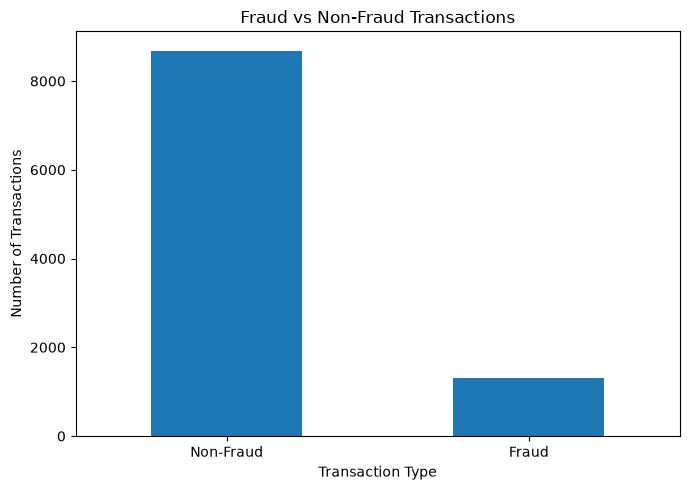

In [80]:
# Create a visualization showing: Fraud vs Non-Fraud 

# Bar chart

Fraud_legitimate_transactions_list = df["Is_Fraud"].value_counts()

Fraud_legitimate_transactions_list.index = ["Non-Fraud", "Fraud"]    # Normal indexes are 0,1 replaced it with Fraud, Non-Fraud.

import matplotlib.pyplot as plt

Fraud_legitimate_transactions_list.plot(kind="bar", figsize=(7, 5))

plt.title("Fraud vs Non-Fraud Transactions")
plt.xlabel("Transaction Type")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [75]:
# (Q.) Is the dataset balanced or imbalanced? 


(Q.) Is the dataset balanced or imbalanced? 

(A.) The dataset is imbalanced. out of 10,000 transactions, 1,314 transaction means 13.14% of fraudulent transaction rate. 

In [ ]:
# Why could class imbalance become a problem in a real fraud detection system? 

(Q.) Why is class imbalance a problem in fraud detection? 

(A.) Because, any ML Model trained on imbalanced data may become biased toward the majority class. It can lead to inaccuracy prediction by the ML Model.

In [ ]:
# Phase 7 – Fraud by Transaction Type 

"""
Analyze fraud across: 
• Online 
• ATM 
• POS 
Create an appropriate visualization. 
"""

fraud_by_type = pd.crosstab(             # pd.crosstab() creates a frequency table showing how two categorical variables are related. ( It counts how many times each combination of values occurs. )
    df["Transaction_Type"],                    # df["Transaction_Type"] = This selects the Transaction_Type column from your DataFrame.
    df["Is_Fraud"]                             # This selects the Fraud column.        0 → Non-Fraud,     1 → Fraud
)

print(fraud_by_type)
print("-----------------------------------------------")



Is_Fraud             0    1
Transaction_Type           
ATM               2086  239
Online            4332  826
POS               2255  247


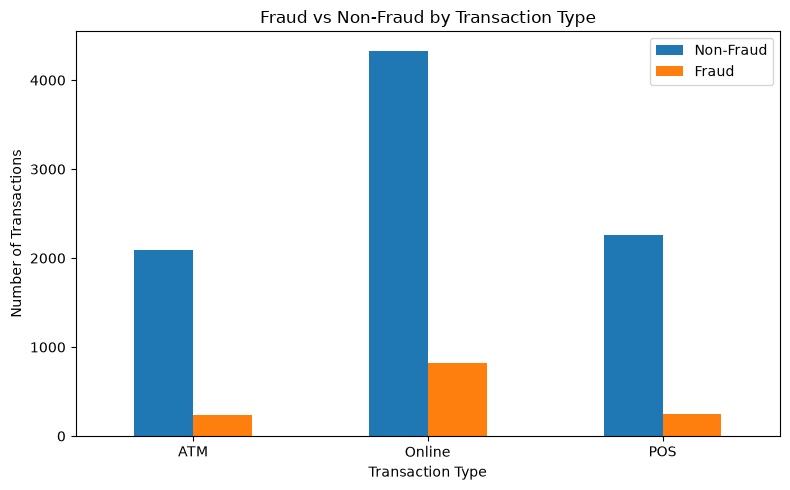

In [83]:
# Bar chart for visualization. 

fraud_by_type = pd.crosstab( df["Transaction_Type"], df["Is_Fraud"] )

fraud_by_type.plot( kind="bar", figsize=(8, 5) )

plt.title("Fraud vs Non-Fraud by Transaction Type")
plt.xlabel("Transaction Type")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=0)
plt.legend(["Non-Fraud", "Fraud"])

plt.tight_layout()
plt.show()


In [81]:
# (1.) 1. Which transaction type has the highest number of fraud cases? 

Questions :-

(1.) Which transaction type has the highest number of fraud cases?  

(A.) Online transaction type have highest number of fraud cases, compared to ATM, POS With 826 Fraud cases. ATM have 239 and POS Have 247 Fraud cases. 

In [ ]:
#  2. Which transaction type has the highest fraud rate? 

(2.) Which transaction type has the highest fraud rate? 

(A.) Online 

Explanation:- 

ATM:             239 / 2325 × 100 = 10.28%

online:          826 / 5158 × 100 = 16.01% 

POS:             247 / 2502 × 100 = 9.87%

Online has the highest fraud rate at approximately 16.01%.


In [ ]:
# (3.) Is online banking more risky than ATM/POS? 

(3.) Is online banking more risky than ATM/POS?
(A.) YES. 

Online transactions have:

Highest number of fraud cases: 826, Highest fraud rate: 16.01%

Compared with:     ATM → 10.28%, POS → 9.87%

Is_Fraud        0    1
Device_Type           
ATM          2089  238
Card         1820  181
Laptop       1478  223
Mobile       3287  669
-----------------------------------------------


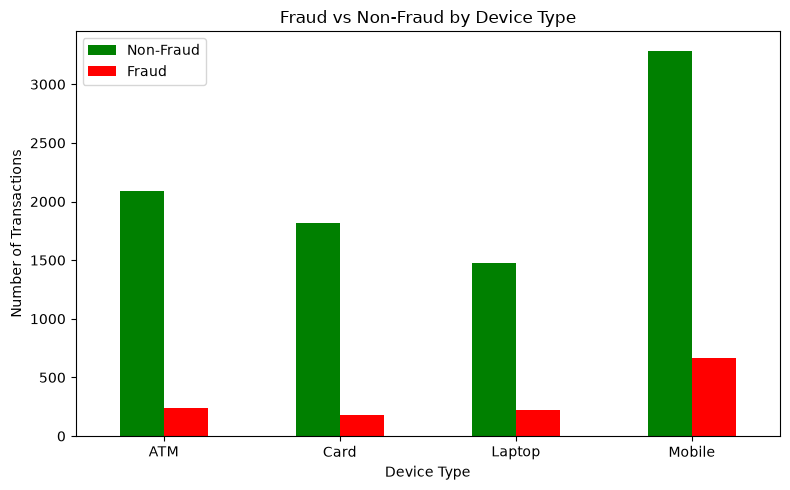

In [86]:
# Phase 8 – Device Analysis 
""" 
Analyze fraud based on: 
• Mobile 
• Laptop 
• ATM 
• Card 
Create suitable visualizations.  """

fraud_by_device = pd.crosstab(            
    df["Device_Type"],                    
    df["Is_Fraud"]                             
)

print(fraud_by_device)
print("-----------------------------------------------")

fraud_by_type = pd.crosstab( df["Device_Type"], df["Is_Fraud"] )

fraud_by_type.plot( kind="bar", figsize=(8, 5) , color = ["green","red"])

plt.title("Fraud vs Non-Fraud by Device Type")
plt.xlabel("Device Type")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=0)
plt.legend(["Non-Fraud", "Fraud"])

plt.tight_layout()
plt.show()


In [ ]:
# 1. Which device is associated with the highest fraud? 

(1.) Which device is associated with the highest fraud? 

(A.) Mobile has the highest number of fraud cases with 669. 

Where as, ATM frauds are 238, Laptop with 223, with Card 181 happend.

In [ ]:
# 2. Does the device type appear to influence fraud? 

(2.) Does device type appear to influence fraud? 

(A.) Yes. There appears to be an association between device type and fraud.

Mobile has the highest fraud rate → 16.91%

Laptop → 13.11%

ATM → 10.23%

Card → 9.05%

In [ ]:
# 3. What percentage of transactions from each device are fraudulent? 

(3.) What percentage of transactions from each device are fraudulent? 

(A.) ATM:-   238 / 2327 × 100 = 10.23%

Card:-      181 / 2001 × 100 = 9.05%

Laptop:-    223 / 1701 × 100 = 13.11% 

Mobile:-    669 / 3956 × 100 = 16.91%

In [ ]:
# (9.) Phase 9 – Location Change Analysis 

# Analyze: Location_Change Compare: Location changed, Location did not change against, Is_Fraud 

fraud_by_location = pd.crosstab( df["Location_Change"], df["Is_Fraud"] )
print(fraud_by_location)

Is_Fraud            0    1
Location_Change           
No               7109  727
Yes              1566  586


In [ ]:
# Are transactions involving a location change more likely to be fraudulent? 

(Q.) Are transactions involving a location change more likely to be fraudulent?

(A.) Yes, based on the given dataset,

No location change have 9.28% fraud 

Location changed have 27.23% fraud, which is 3 times higher than No location change. 

In [93]:
# Create a visualization and calculate the fraud percentage for each group. 

(Q.) Calculate fraud percentage for each group

(A.) Fraud Percentage = (Fraud Transactions / Total Transactions) × 100 

Location did not change:- Total = 7109 + 727 = 7836,  Fraud % = 727 / 7836 × 100 = 9.28% 

Location changed:- Total = 1566 + 586 = 2152, Fraud % = 586 / 2152 × 100 = 27.23%

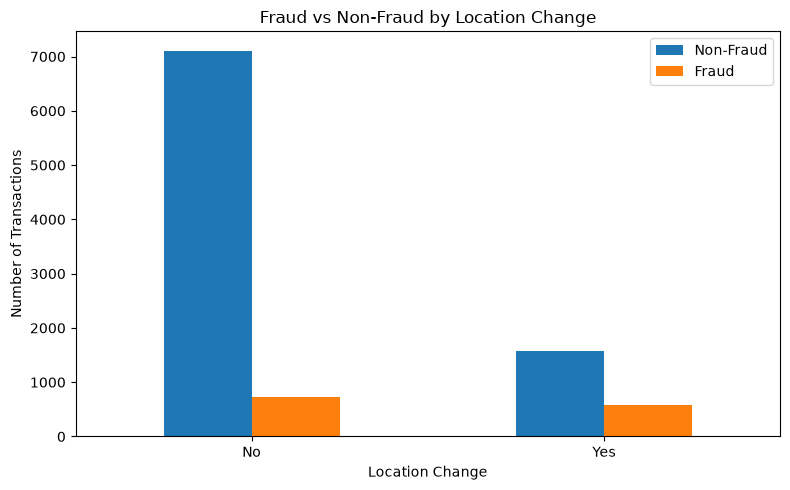

In [92]:
# Graph

fraud_by_location = pd.crosstab( df["Location_Change"], df["Is_Fraud"] )

# Create visualization
fraud_by_location.plot( kind="bar", figsize=(8, 5) )

plt.title("Fraud vs Non-Fraud by Location Change")
plt.xlabel("Location Change")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=0)
plt.legend(["Non-Fraud", "Fraud"])

plt.tight_layout()
plt.show()

In [8]:
# Phase 10 – Transaction Time Analysis 

# Create a new column: Time_Category 

def Time_Category_func(Time):         # create a function, takes time and return a category.
    if ( Time >= 5 and Time <=11 ):
        return "Morning" 
    elif ( Time >= 12 and Time <=16 ):
        return "Afternoon" 
    elif ( Time >= 17 and Time <=20 ):
        return "Evening" 
    elif ( Time >= 21 and Time <=23 ):
        return "Night"
    elif ( Time >= 0 and Time <=4 ):
        return "Late Night" 

df["Time_Category"] = df["Transaction_Time_Hour"].apply(Time_Category_func)  # we take Transaction time hour, and apply in Time_Category_func to take appropriate category.

# Time_Category holds the Time category for each transaction time. 

print(df[["Transaction_Time_Hour", "Time_Category"]].head(10))


   Transaction_Time_Hour Time_Category
0                   10.0       Morning
1                   17.0       Evening
2                    4.0    Late Night
3                   20.0       Evening
4                   11.0       Morning
5                    0.0    Late Night
6                   21.0         Night
7                   15.0     Afternoon
8                    7.0       Morning
9                   20.0       Evening


In [10]:
# Analyze fraud across different time periods. 

fraud_across_timeperiods = pd.crosstab(df["Time_Category"],df["Is_Fraud"])
print(fraud_across_timeperiods)

Is_Fraud          0    1
Time_Category           
Afternoon      2003  278
Evening        1957  254
Late Night      671  200
Morning        2956  439
Night          1072  139


In [29]:
# 1. During which time period does fraud occur most frequently? 

fraud_percentage_time = df.groupby("Time_Category")["Is_Fraud"].mean() * 100

print(fraud_percentage_time)
print("--------------------------------------------------")

print("max_time_fraud_period:- ",fraud_percentage_time.idxmax())
print("number_of_fruads_max_fruad_period:- ",fraud_percentage_time.max() )

Time_Category
Afternoon     12.187637
Evening       11.488014
Late Night    22.962113
Morning       12.930781
Night         11.478117
Name: Is_Fraud, dtype: float64
--------------------------------------------------
max_time_fraud_period:-  Late Night
number_of_fruads_max_fruad_period:-  22.962112514351322


In [ ]:
# 2. Are late-night transactions more suspicious? 

(2.) Are late-night transactions more suspicious? 

(A.) After calculating percentages of all timeperiods, late night period frauds are double than any other period. So, there is high probability that, most suspicious transactions happens at late night.

In [ ]:
# 3. Is transaction time a useful fraud indicator? 

(3.) Is transaction time a useful fraud indicator? 

(A.) Probably yes, if the fraud rates differ meaningfully across the time categories. 

Example:- If late-night transactions have a substantially higher fraud rate than daytime transactions, transaction time may be a useful fraud indicator.

In [16]:
# Phase 11 – Failed Transactions Analysis 

print(pd.crosstab(df["Failed_Transactions_Last_24h"],df["Is_Fraud"]))


Is_Fraud                         0    1
Failed_Transactions_Last_24h           
0.0                           3693  522
1.0                           3230  469
2.0                           1383  179
3.0                            295  118
4.0                             57   19
5.0                             14    6


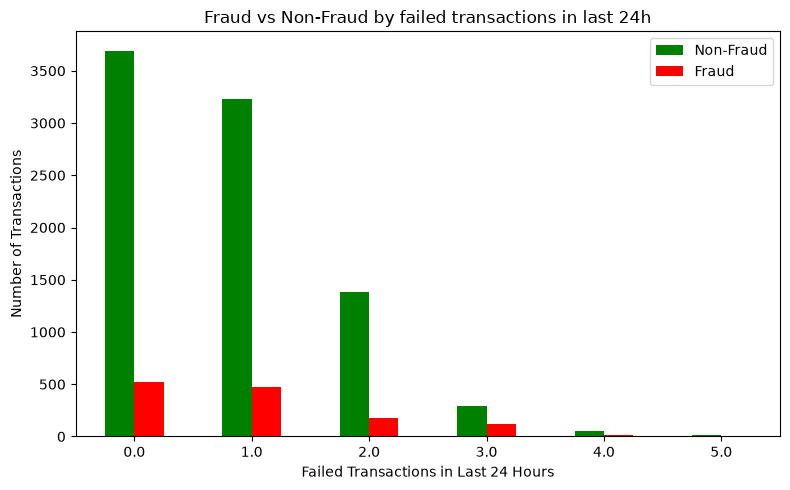

In [ ]:
# Create a visualization. 
import matplotlib.pyplot as plt
fraud_Failed_Transaction_in_last_24h = pd.crosstab(df["Failed_Transactions_Last_24h"],df["Is_Fraud"])

fraud_Failed_Transaction_in_last_24h.plot( kind="bar", figsize=(8, 5), color = ["green","red"] )

plt.title("Fraud vs Non-Fraud by failed transactions in last 24h")
plt.xlabel("Failed Transactions in Last 24 Hours")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=0)
plt.legend(["Non-Fraud", "Fraud"])

plt.tight_layout()
plt.show()

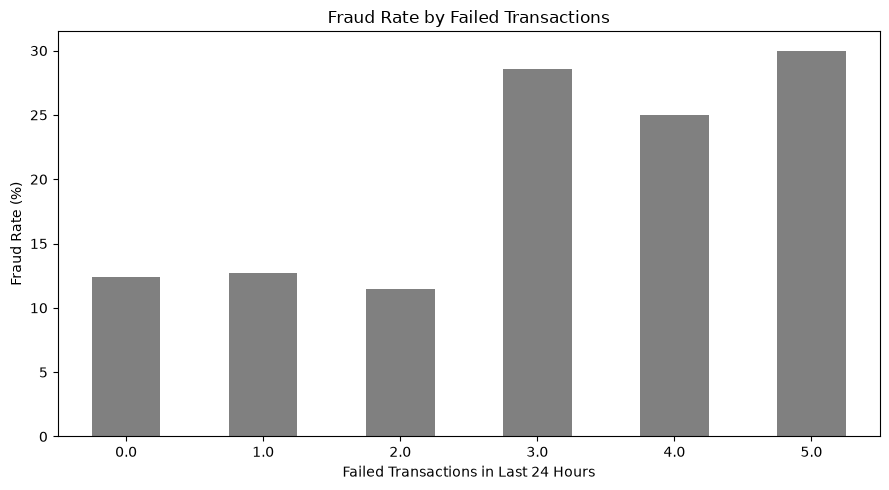

In [30]:
# Fraud percentage visualization

fraud_rate_failed = ( df.groupby("Failed_Transactions_Last_24h")["Is_Fraud"].mean() * 100)

fraud_rate_failed.plot( kind="bar", figsize=(9, 5), color = "gray", )

plt.title("Fraud Rate by Failed Transactions")
plt.xlabel("Failed Transactions in Last 24 Hours")
plt.ylabel("Fraud Rate (%)")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

In [33]:
# 1. Do fraudulent transactions have more failed attempts?

avg_failed = df.groupby("Is_Fraud")["Failed_Transactions_Last_24h"].mean()

print(avg_failed)

Is_Fraud
0    0.827837
1    0.980198
Name: Failed_Transactions_Last_24h, dtype: float64


Answer:-

Fraudulent transactions: ≈ 0.98 failed attempts

Non-fraudulent transactions: ≈ 0.83 failed attempts

Yes. Fraudulent transactions have a higher average number of failed attempts than non-fraudulent transactions.

In [37]:
# 2. What is the average number of failed transactions for fraud cases? 

Average_no_failed_transactions_for_fraud = df[df["Is_Fraud"] == 1.0]["Failed_Transactions_Last_24h"].mean()
print("Average failed transactions for fraud cases:",Average_no_failed_transactions_for_fraud)

Average failed transactions for fraud cases: 0.9801980198019802


In [42]:
# 3. Does a higher number of failed transactions indicate increased risk?

failed_fraud = pd.crosstab(df["Failed_Transactions_Last_24h"],df["Is_Fraud"])
total_transactions = failed_fraud.sum(axis=1)

fraud_rate = (failed_fraud[1] / failed_fraud.sum(axis=1)) * 100
print(fraud_rate)

Failed_Transactions_Last_24h
0.0    12.384342
1.0    12.679102
2.0    11.459667
3.0    28.571429
4.0    25.000000
5.0    30.000000
dtype: float64


Yes. 3 or more failed transactions are associated with a noticeably higher fraud rate in given dataset.

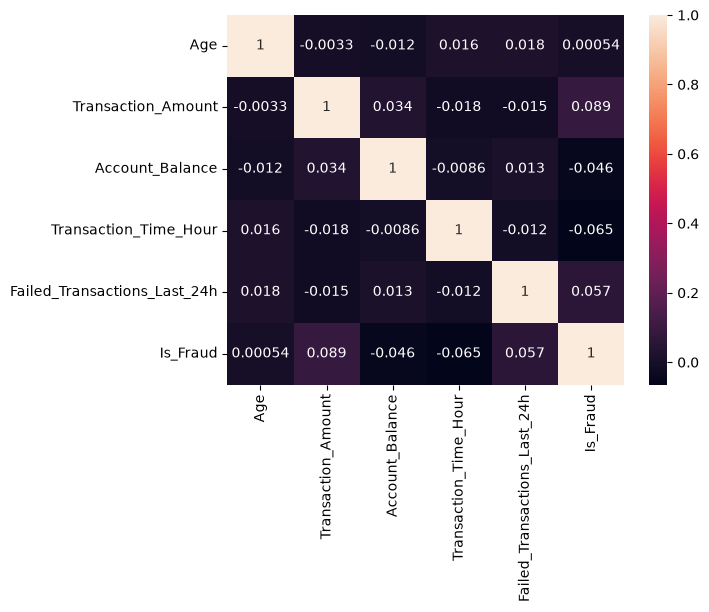

In [52]:
# Phase 12 – Correlation Analysis 
numerical_col = df.select_dtypes(include = "number")

import seaborn as sns 

correlation_between_numericals = df.corr(numeric_only = True) 
sns.heatmap(correlation_between_numericals,annot=True) 
plt.show()

In [ ]:
# 1. Which variables have the strongest relationship with fraud? 

(1.) Which variables have the strongest relationship with fraud?

(A.) Transaction_Aount has strongest relationship with fraud compared to remaining numerical columns, but the relationship is still very weak.

corr_value => Transaction_Amount (+0.089) > Failed_Transactions_Last_24h (+0.057)

In [ ]:
# 2. Which variables appear unrelated? 

(2.) Which variables appear unrelated?

(A.) Variables which is close to 0 are unrelated. In heat map, value that close to 0 is 0.00054 between Age and Is_Fraud. 

Age appears to have almost no linear relationship with fraud in this dataset.

In [53]:
# 3. Are there highly correlated independent variables? 

(3.) Are there highly correlated independent variables? 

(A.) The highest independent variable correlation in heatmap is, 0.034 between Transaction_Amount, Account_Balance. Remaining are less than 0.015. These are all very close to zero.

So, There are no highly correlated independent variables in this dataset. 

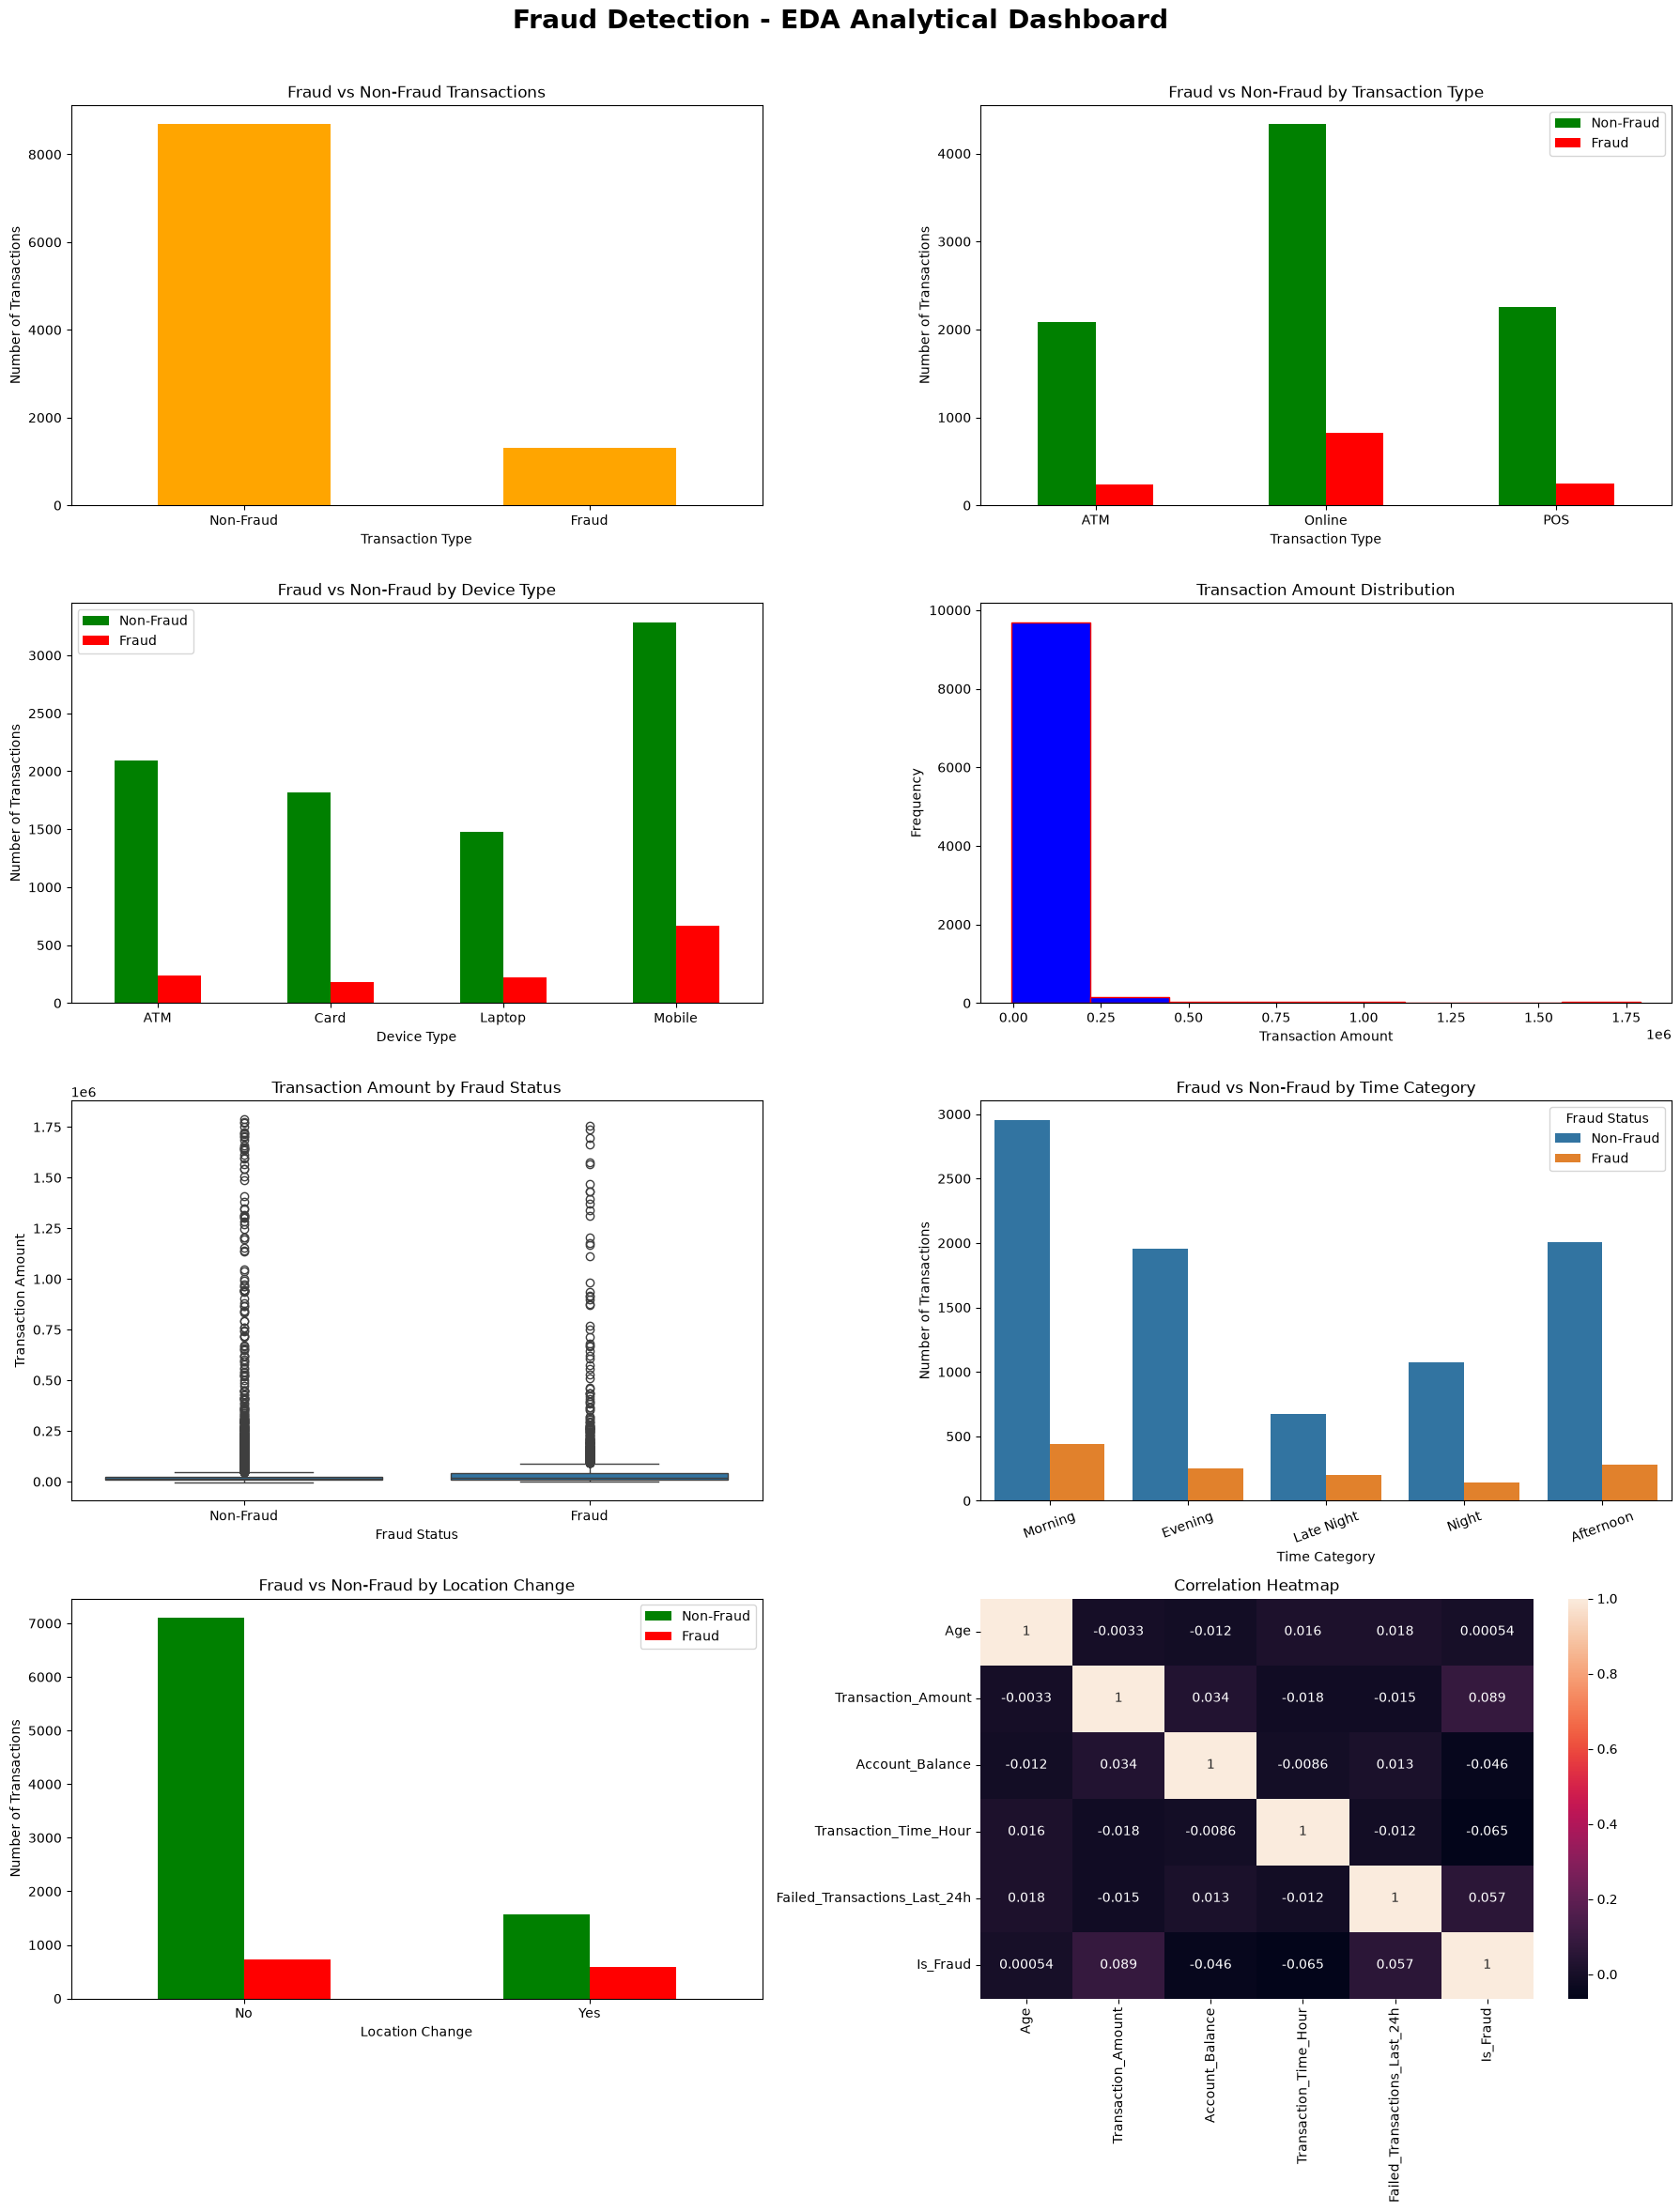

In [88]:
# Phase 13 – Visualization Dashboard

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Create dashboard
fig, axes = plt.subplots(4, 2, figsize=(18, 24))

# 1. Fraud vs Non-Fraud

fraud_counts = df["Is_Fraud"].value_counts()

fraud_counts.index = ["Non-Fraud", "Fraud"]

fraud_counts.plot(
    kind="bar",
    ax=axes[0, 0],
    color="orange"
)

axes[0, 0].set_title("Fraud vs Non-Fraud Transactions")
axes[0, 0].set_xlabel("Transaction Type")
axes[0, 0].set_ylabel("Number of Transactions")
axes[0, 0].tick_params(axis="x", rotation=0)

# 2. Fraud by Transaction Type

fraud_by_type = pd.crosstab(
    df["Transaction_Type"],
    df["Is_Fraud"]
)

fraud_by_type.plot(
    kind="bar",
    ax=axes[0, 1],
    color=["green", "red"]
)

axes[0, 1].set_title("Fraud vs Non-Fraud by Transaction Type")
axes[0, 1].set_xlabel("Transaction Type")
axes[0, 1].set_ylabel("Number of Transactions")
axes[0, 1].tick_params(axis="x", rotation=0)
axes[0, 1].legend(["Non-Fraud", "Fraud"])

# 3. Fraud by Device Type

fraud_by_device = pd.crosstab(
    df["Device_Type"],
    df["Is_Fraud"]
)

fraud_by_device.plot(
    kind="bar",
    ax=axes[1, 0],
    color=["green", "red"]
)

axes[1, 0].set_title("Fraud vs Non-Fraud by Device Type")
axes[1, 0].set_xlabel("Device Type")
axes[1, 0].set_ylabel("Number of Transactions")
axes[1, 0].tick_params(axis="x", rotation=0)
axes[1, 0].legend(["Non-Fraud", "Fraud"])


# 4. Transaction Amount Distribution

axes[1, 1].hist(
    df["Transaction_Amount"].dropna(),
    bins=8,
    color="blue",
    edgecolor="red"
)

axes[1, 1].set_title("Transaction Amount Distribution")
axes[1, 1].set_xlabel("Transaction Amount")
axes[1, 1].set_ylabel("Frequency")

# 5. Transaction Amount by Fraud Status

sns.boxplot(
    data=df,
    x="Is_Fraud",
    y="Transaction_Amount",
    ax=axes[2, 0]
)

axes[2, 0].set_title("Transaction Amount by Fraud Status")
axes[2, 0].set_xlabel("Fraud Status")
axes[2, 0].set_ylabel("Transaction Amount")

axes[2, 0].set_xticks(
    [0, 1],
    ["Non-Fraud", "Fraud"]
)

# 6. Fraud by Time Category

sns.countplot(
    data=df,
    x="Time_Category",
    hue="Is_Fraud",
    ax=axes[2, 1]
)

axes[2, 1].set_title("Fraud vs Non-Fraud by Time Category")
axes[2, 1].set_xlabel("Time Category")
axes[2, 1].set_ylabel("Number of Transactions")

axes[2, 1].tick_params(axis="x", rotation=20)

axes[2, 1].legend(
    title="Fraud Status",
    labels=["Non-Fraud", "Fraud"]
)

# 7. Fraud vs Location Change

fraud_by_location = pd.crosstab(
    df["Location_Change"],
    df["Is_Fraud"]
)

fraud_by_location.plot(
    kind="bar",
    ax=axes[3, 0],
    color=["green", "red"]
)

axes[3, 0].set_title("Fraud vs Non-Fraud by Location Change")
axes[3, 0].set_xlabel("Location Change")
axes[3, 0].set_ylabel("Number of Transactions")
axes[3, 0].tick_params(axis="x", rotation=0)
axes[3, 0].legend(["Non-Fraud", "Fraud"])


# 8. Correlation Heatmap

correlation = df.corr(numeric_only=True)

sns.heatmap(
    correlation,
    annot=True,
    ax=axes[3, 1]
)

axes[3, 1].set_title("Correlation Heatmap")


# Dashboard layout

plt.suptitle(
    "Fraud Detection - EDA Analytical Dashboard",
    fontsize=20,
    fontweight="bold"
)

plt.tight_layout(
    rect=[0, 0, 1, 0.97]
)

plt.show()

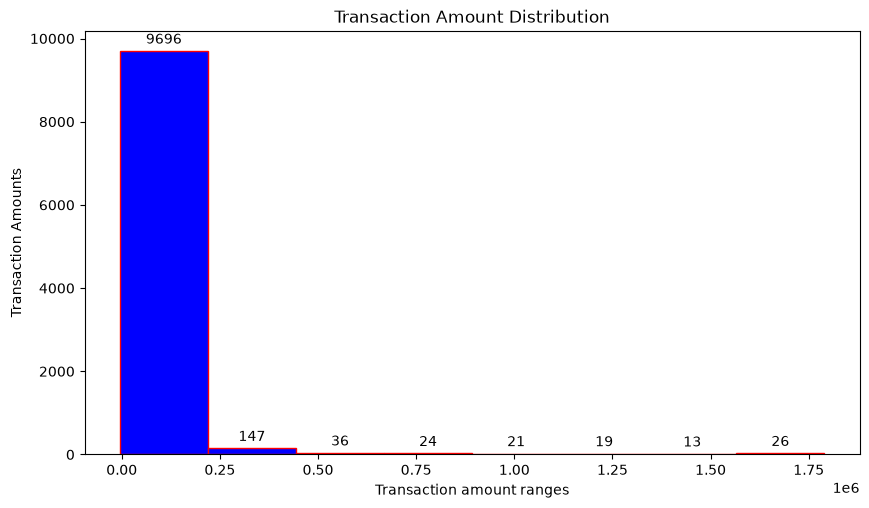

In [69]:
# 4. Transaction Amount Distribution 

fig, ax = plt.subplots(figsize = (10,5.5))
n, bins, patches = ax.hist(df["Transaction_Amount"],bins = 8, color = "blue", edgecolor = "red" )

ax.bar_label( patches, labels=[str(int(value)) for value in n],padding=3)

ax.set_title("Transaction Amount Distribution")
ax.set_xlabel("Transaction amount ranges") 
ax.set_ylabel("Transaction Amounts")
plt.show()

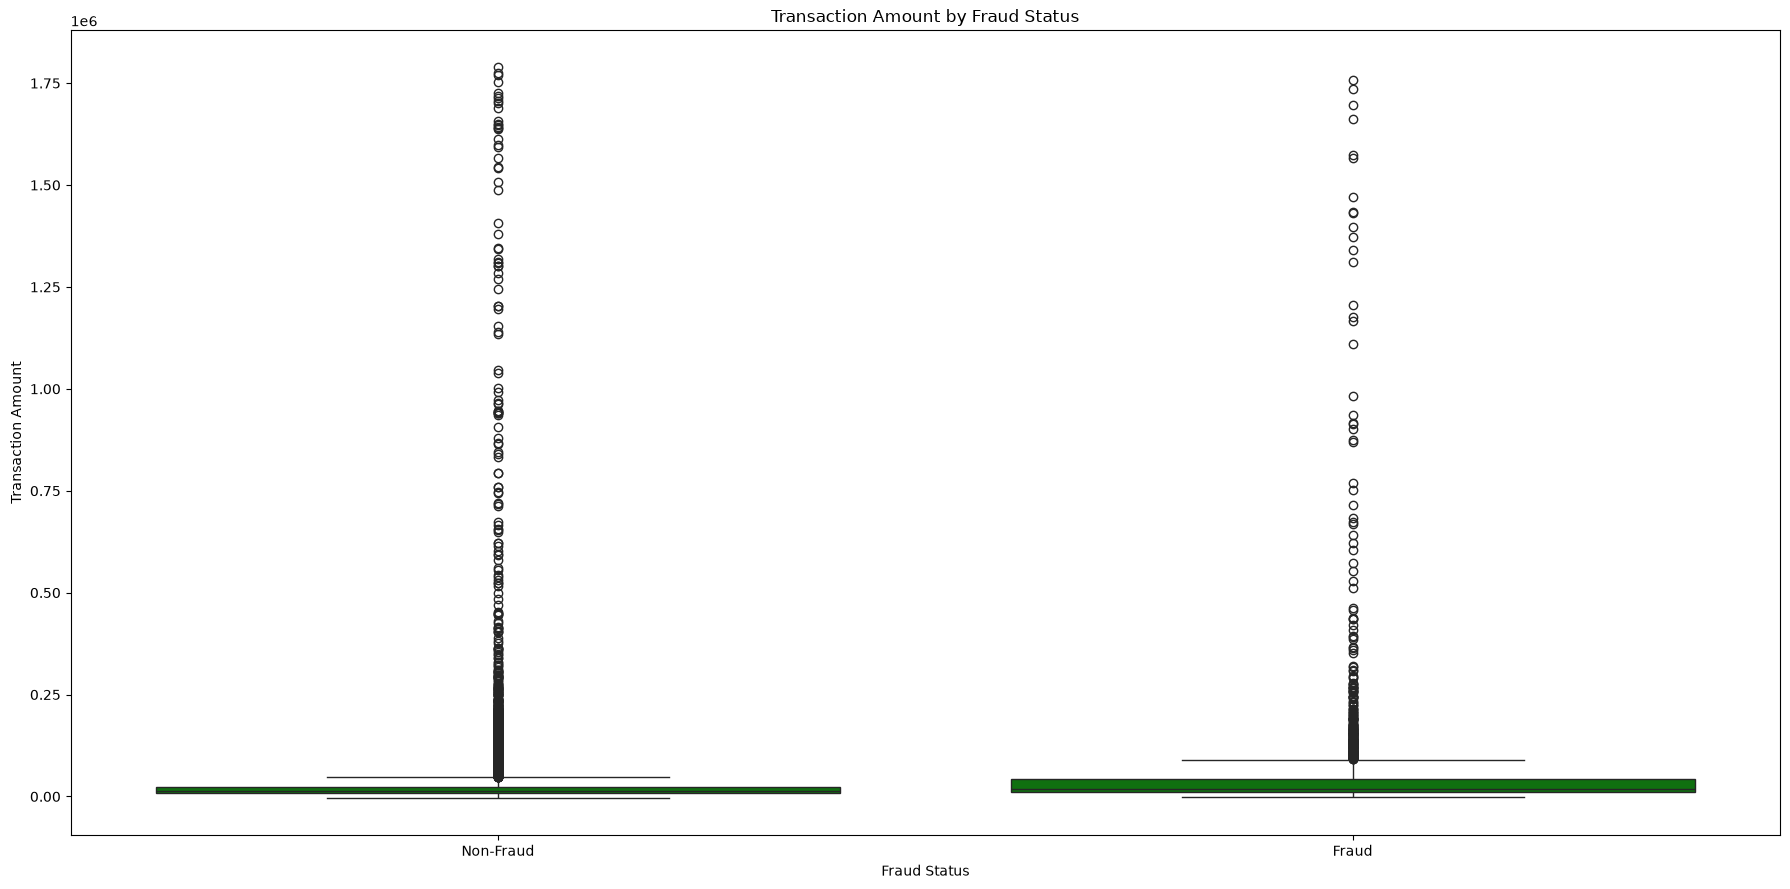

In [73]:
# 5. ) Transaction Amount by Fraud Status 
plt.figure(figsize=(18,9))

sns.boxplot( data=df, x="Is_Fraud", y="Transaction_Amount", color = "green")

plt.title("Transaction Amount by Fraud Status")
plt.xlabel("Fraud Status")
plt.ylabel("Transaction Amount")
plt.xticks( ticks=[0, 1], labels=["Non-Fraud", "Fraud"])

plt.tight_layout()
plt.show()

In [83]:
def Time_Category_func(Time):         # create a function, takes time and return a category.
    if ( Time >= 5 and Time <=11 ):
        return "Morning" 
    elif ( Time >= 12 and Time <=16 ):
        return "Afternoon" 
    elif ( Time >= 17 and Time <=20 ):
        return "Evening" 
    elif ( Time >= 21 and Time <=23 ):
        return "Night"
    elif ( Time >= 0 and Time <=4 ):
        return "Late Night" 

df["Time_Category"] = df["Transaction_Time_Hour"].apply(Time_Category_func)  

print(df[["Transaction_Time_Hour", "Time_Category"]].head(10))

   Transaction_Time_Hour Time_Category
0                   10.0       Morning
1                   17.0       Evening
2                    4.0    Late Night
3                   20.0       Evening
4                   11.0       Morning
5                    0.0    Late Night
6                   21.0         Night
7                   15.0     Afternoon
8                    7.0       Morning
9                   20.0       Evening


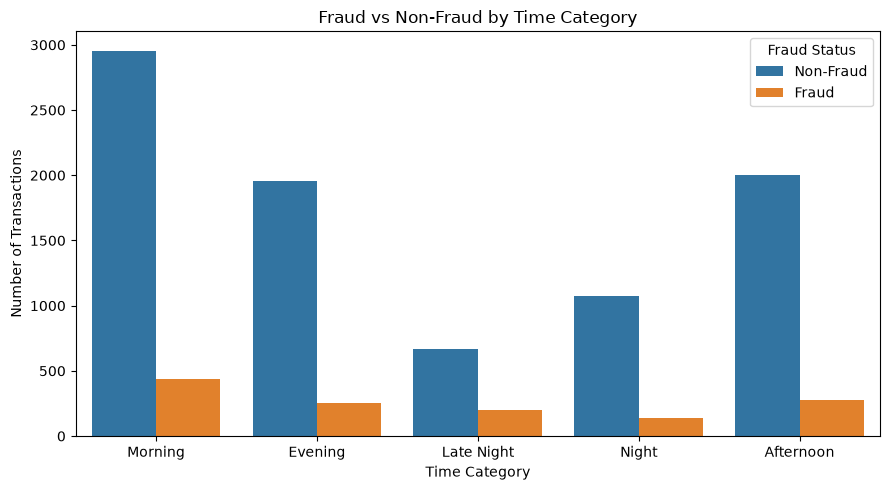

In [84]:
# 6. ) Fraud by Time Category 
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="Time_Category",
    hue="Is_Fraud"
)

plt.title("Fraud vs Non-Fraud by Time Category")
plt.xlabel("Time Category")
plt.ylabel("Number of Transactions")

plt.legend( title="Fraud Status", labels=["Non-Fraud", "Fraud"])

plt.tight_layout()
plt.show()

In [97]:
# Phase 14 – Feature Engineering 

# Feature 1 – Transaction Ratio               (Transaction_Ratio = Transaction_Amount / Account_Balance )

df["Transaction_Ratio"] = df["Transaction_Amount"] / df["Account_Balance"] 

print(df[["Transaction_Ratio","Transaction_Amount","Account_Balance"]])

      Transaction_Ratio  Transaction_Amount  Account_Balance
0              1.724314            20165.96         11695.06
1              1.185915            80057.08         67506.61
2              0.259133            11593.67         44740.16
3              0.042782            11208.39        261985.75
4              0.592498            12673.87         21390.58
...                 ...                 ...              ...
9995           0.197790            20955.86        105949.88
9996           1.083858            22601.72         20853.03
9997           0.155357            17599.32        113282.82
9998           0.029835             6188.04        207406.67
9999           0.937584            22368.53         23857.63

[10000 rows x 3 columns]


In [102]:
# Feature 2 – Is_High_Value 

df["Is_High_Value"] = np.where( df["Transaction_Amount"] > 100000, "Yes", "No" )
print(df[["Transaction_Amount","Is_High_Value"]].head(10))

   Transaction_Amount Is_High_Value
0            20165.96            No
1            80057.08            No
2            11593.67            No
3            11208.39            No
4            12673.87            No
5            44335.95            No
6           276648.97           Yes
7            17970.66            No
8           290207.48           Yes
9            17242.28            No


In [104]:
# Feature 3 – High_Risk_Time 

df["High_Risk_Time"] = np.where( df["Transaction_Time_Hour"].between(0, 4), "Yes", "No" ) 
print(df[["Transaction_Time_Hour","High_Risk_Time"]].head(10))

   Transaction_Time_Hour High_Risk_Time
0                   10.0             No
1                   17.0             No
2                    4.0            Yes
3                   20.0             No
4                   11.0             No
5                    0.0            Yes
6                   21.0             No
7                   15.0             No
8                    7.0             No
9                   20.0             No


In [112]:
# Feature 4 – High_Failed_Attempts

df["High_Failed_Attempts"] = np.where(df["Failed_Transactions_Last_24h"] >= 3, "Yes", "No")
print(df[["Failed_Transactions_Last_24h","High_Failed_Attempts"]].tail(20))

      Failed_Transactions_Last_24h High_Failed_Attempts
9980                           1.0                   No
9981                           1.0                   No
9982                           4.0                  Yes
9983                           0.0                   No
9984                           0.0                   No
9985                           1.0                   No
9986                           1.0                   No
9987                           1.0                   No
9988                           0.0                   No
9989                           1.0                   No
9990                           1.0                   No
9991                           2.0                   No
9992                           1.0                   No
9993                           0.0                   No
9994                           1.0                   No
9995                           1.0                   No
9996                           1.0              

In [114]:
# Phase 15 – Identify Suspicious Transactions 

# Potentially Suspicious

df["Potentially_Suspicious"] = np.where(
    (
        (df["Is_High_Value"] == "Yes") |
        (df["Location_Change"] == "Yes") |
        (df["High_Risk_Time"] == "Yes") |
        (df["High_Failed_Attempts"] == "Yes") |
        (df["Transaction_Ratio"] > 1)
    ),
    "Yes",
    "No"
)
print( df["Potentially_Suspicious"].value_counts() )

Potentially_Suspicious
No     5551
Yes    4449
Name: count, dtype: int64


In [117]:
suspicious_transactions = df[ df["Potentially_Suspicious"] == "Yes" ]
print(suspicious_transactions.head(5))

  Transaction_ID Customer_ID   Age       City  Transaction_Amount  \
0      TXN000001   CUST00224  51.0     Mumbai            20165.96   
1      TXN000002   CUST01935  27.0  Bengaluru            80057.08   
2      TXN000003   CUST01637  37.0  Bengaluru            11593.67   
5      TXN000006   CUST02147  22.0    Chennai            44335.95   
6      TXN000007   CUST00215  62.0    Chennai           276648.97   

  Transaction_Type  Account_Balance Device_Type Location_Change  \
0              ATM         11695.06         ATM              No   
1           Online         67506.61      Mobile             Yes   
2              POS         44740.16      Mobile             Yes   
5           Online         59945.82      Mobile              No   
6           Online         98553.66      Mobile              No   

   Transaction_Time_Hour Is_Weekend  Failed_Transactions_Last_24h  Is_Fraud  \
0                   10.0        Yes                           0.0         0   
1                   17.0

In [6]:
# Final Business Questions 

# (1.) What are the strongest indicators of fraudulent transactions? 

(1.) What are the strongest indicators of fraudulent transactions? 

(A.) 
(i.) Location Change

No location change → 9.28% fraud, Location changed → 27.23% fraud. This is a substantial difference.

(ii.) Multiple Failed Transactions

3 failed → 28.57%, 
4 failed → 25.00%, 
5 failed → 30.00%, 
Particularly 3+ failed attempts are associated with higher fraud rates.

(iii.) Device Type

Mobile → 16.91% fraud, Laptop → 13.11%

(iv.) Transaction Type

Online → 16.01%, ATM → 10.28%, POS → 9.87%

(v.)Transaction Amount

It had the strongest numerical correlation with Is_Fraud, but the correlation was only +0.089, which is weak.

In [5]:
# (2.) Are high-value transactions more likely to be fraudulent? 

(2.) Are high-value transactions more likely to be fraudulent? 

(A.) 

They show a weak positive relationship with fraud (+0.089).
High-value transactions should be investigated, not automatically marked as fraud.

In [7]:
# (3.) Does a location change indicate higher fraud risk? 

(3.) Does a location change indicate higher fraud risk? 

(A.) Yes. Transactions involving a location change show a substantially higher fraud rate with 27.23% and should receive additional scrutiny. However, a location change alone does not prove fraud.

In [8]:
# 4.) Does transaction time influence fraud? 

(4.) Does transaction time influence fraud? 

(A.) Correlation between Transaction_Time_Hour, Is_Fraud is -0.065. This is a very weak linear relationship. So, Time can be used as a supporting indicator, not a standalone rule.

In [9]:
# 5.) Does the number of failed transactions correlate with fraud? 

(5.) Does the number of failed transactions correlate with fraud? 

(A.)  Yes, especially 3+ failed attempts. 3 failed → 28.57% fraud, 5 failed → 30% fraud

In [4]:
# 6.) Which transaction type has the highest fraud rate? 

(6.) Which transaction type has the highest fraud rate? 
(A.) 

Online transactions have the highest fraud rate at approximately 16.01%, making Online the transaction type that deserves greater monitoring in this dataset.

In [ ]:
# 7.) Which device type has the highest fraud rate? 

(7.) Which device type has the highest fraud rate? 

(A.)

Mobile transactions have the highest fraud rate at approximately 16.91%. This suggests that mobile transactions deserve additional monitoring, although this does not mean mobile devices cause fraud.

In [ ]:
# 8.) Are outliers necessarily fraudulent? 

(8.) Are outliers necessarily fraudulent? 

(A.) No. An outlier only means that the observation is unusually high or low compared with the rest of the data.

In [ ]:
# 9.) Which variables should the bank monitor more closely? 

(9.) Which variables should the bank monitor more closely?

(A.) 

Location Change

Failed Transactions

Transaction Type

Device Type

Transaction Amount

Transaction/Balance Ratio

Transaction Time

In [ ]:
# 10.) What recommendations would you give to the bank? 

(10.) What recommendations would you give to the bank? 

(A.) 

Use multiple fraud indicators together.

Give extra verification for location changes + failed attempts.

Monitor Online and Mobile transactions closely.

Don't automatically reject high-value transactions or outliers.

Use a risk-scoring system instead of a single rule.

Evaluate ML models using Precision, Recall, F1-score, not accuracy alone.

----------------------------------------------------------------------------------------------------------

(11.) Fraud Pattern Analysis

The analysis identified several patterns associated with fraudulent transactions:

**Location changes** show a higher fraud rate of **27.23%** compared with **9.28%** without a location change.

**Online transactions** have the highest fraud rate among transaction types at **16.01%**.

**Mobile transactions** have the highest fraud rate among device types at **16.91%**.

**Transactions** with **3 or more failed attempts** show a noticeably higher fraud rate.

**Transaction** amount has a **weak positive relationship** with fraud.

Outliers are not automatically considered fraudulent and require further investigation.

----------------------------------------------------------------------------------------------------------


(12.) Key Insights 

(A.)

Location change is one of the strongest suspicious indicators.

Multiple failed transactions can indicate increased fraud risk.

Online and Mobile transactions show relatively higher fraud rates.

High-value transactions should be monitored but not automatically classified as fraud.

The dataset is imbalanced, with 13.14% fraud and 86.86% non-fraud transactions.

----------------------------------------------------------------------------------------------------------

Expected Final Conclusion 

Key Findings:-

Finding 1: Transactions with a location change have a higher fraud rate (27.23%) compared with transactions without a location change (9.28%).

Finding 2: Online transactions have the highest fraud rate among transaction types (16.01%).

Finding 3: Mobile devices have the highest fraud rate among device types (16.91%).

Finding 4: Transactions with 3 or more failed attempts show a noticeably higher fraud rate.

Finding 5: High-value transactions and outliers can be useful warning signals, but they should not automatically be considered fraudulent.

------------------------------------------------------------------------------------------------------------

Business Recommendations

Recommendation 1: Closely monitor transactions involving location changes, multiple failed attempts, Online transactions, and Mobile devices.

Recommendation 2: Use multiple indicators together to create a fraud risk score instead of relying on a single condition.

Recommendation 3: Send high-risk transactions for additional verification or investigation rather than automatically blocking legitimate transactions.

-----------------------------------------------------------------------------------------------------------

Conclusion :-

The analysis identified several transaction characteristics associated with higher fraud risk, particularly location changes, multiple failed attempts, Online transactions, and Mobile devices. These indicators can be combined to identify potentially suspicious transactions for further investigation. However, no single indicator should be treated as definitive proof of fraud.